# Experiment 8: Abstractive Text Summarization using mT5 and mBART

**Aim:** To implement and evaluate abstractive text summarization using two multilingual Transformer-based sequence-to-sequence models, mT5 (Multilingual Text-to-Text Transfer Transformer) and mBART (Multilingual Bidirectional and Auto-Regressive Transformers), on one language (Hindi) of the XL-Sum (Cross-Lingual Summarization) dataset, and to compare them using ROUGE-1, ROUGE-2, ROUGE-L (Recall-Oriented Understudy for Gisting Evaluation) and BERTScore computed with mBERT (multilingual BERT).

**Dataset:** XL-Sum, Hindi subset (`csebuetnlp/xlsum`): BBC (British Broadcasting Corporation) news articles (`text`) paired with a professionally written one-sentence summary (`summary`).

**Models:** `google/mt5-small` and `facebook/mbart-large-50`, both fine-tuned on the same Hindi training subset.

**Parts:**
1. Setup, data loading and evaluation helpers
2. mT5 (fine-tune, generate, evaluate)
3. mBART (fine-tune, generate, evaluate)
4. Comparative analysis

## Part 1: Setup, Data Loading and Evaluation Helpers

**Language choice (Hindi):** it is a large XL-Sum language with plenty of training data, is written in the Devanagari script, and is the easiest to read and verify for our class.

**Subset (3,000 train / 300 test articles):** fine-tuning two Transformers on the full data would take many hours on a free GPU (Graphics Processing Unit). A fixed random subset keeps the run practical, and both models see exactly the same data, so the comparison is fair. Scores will be lower than published results that use the full data.

**Why fine-tune:** the raw pretrained models only know how to fill in masked text, not how to summarize, so they must be fine-tuned first.

**Evaluation:** ROUGE measures word overlap with the reference summary (ROUGE-1 = single words, ROUGE-2 = word pairs, ROUGE-L = longest common sequence). A custom Hindi tokenizer is needed because the default one deletes Devanagari characters. BERTScore compares meaning using mBERT embeddings, so it can credit a correct summary that uses different words.

In [1]:
# Cell 1: install libraries (Internet must be ON)
!pip install -q transformers sentencepiece protobuf rouge_score bert_score huggingface_hub tqdm

In [2]:
# Cell 2: download the Hindi parquet files and load them with pandas
import os, glob, random
import numpy as np
import pandas as pd
import torch
from huggingface_hub import HfApi, snapshot_download

random.seed(42); np.random.seed(42); torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)          # must print "cuda"

# the dataset script is no longer supported, so we read the parquet files directly.
# the parquet files live on the auto-converted branch "refs/convert/parquet"
files, path = [], None
for revision in ["refs/convert/parquet", "main"]:
    repo_files = HfApi().list_repo_files("csebuetnlp/xlsum", repo_type="dataset", revision=revision)
    hindi = [f for f in repo_files if f.startswith("hindi/") and f.endswith(".parquet")]
    print(revision, "->", hindi)                 # shows which files exist on this branch
    if hindi:
        path = snapshot_download("csebuetnlp/xlsum", repo_type="dataset",
                                 revision=revision, allow_patterns=hindi)
        files = [os.path.join(path, f) for f in hindi]
        break

assert files, "No Hindi parquet files found. Send me the lines printed above."

def load_split(split):
    parts = [pd.read_parquet(f) for f in sorted(files) if split in os.path.relpath(f, path)]
    return pd.concat(parts, ignore_index=True).drop_duplicates("id")   # id removes accidental repeats

train_full, test_full = load_split("train"), load_split("test")
print(train_full.shape, test_full.shape)
print(train_full.columns.tolist())

Device: cuda
refs/convert/parquet -> ['hindi/test/0000.parquet', 'hindi/train/0000.parquet', 'hindi/train/0001.parquet', 'hindi/validation/0000.parquet']


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

(70778, 5) (8847, 5)
['id', 'url', 'title', 'summary', 'text']


In [3]:
# Cell 3: take a fixed random subset (same data for both models)
TRAIN_N, TEST_N = 3000, 300
train_df = train_full.sample(TRAIN_N, random_state=42).reset_index(drop=True)
test_df = test_full.sample(TEST_N, random_state=42).reset_index(drop=True)

print(train_df.loc[0, "text"][:300], "\n")
print("SUMMARY:", train_df.loc[0, "summary"])
print("avg article chars:", int(train_df["text"].str.len().mean()),
      "| avg summary chars:", int(train_df["summary"].str.len().mean()))

जंग अख़बार में अफ़ज़ाल रेहान ने एक लेख लिखा है जिसका शीर्षक है 'भारतीय चुनावों में विजेता कौन?' अफ़ज़ाल कहते हैं कि अपने सियासी फ़ायदे के लिए मोदी ने जिस तरह से पाकिस्तान के ख़िलाफ़ बयानबाज़ी की है और जिस तरह झूठ पर झूठ बोले उनकी बुनियाद पर अगर वो चुनाव जीत भी जाते हैं तो भी ऐतिहासिक तौर पर वो बड़े  

SUMMARY: पाकिस्तान से छपे उर्दू अख़बारों में इस हफ़्ते भारत में चल रहे लोकसभा चुनावों और उससे जुड़े इमरान ख़ान के बयान को लेकर काफ़ी कुछ लिखा गया जिसमें उन्होंने कहा था कि मोदी की जीत से कश्मीर संकट के सुलझने की संभावना ज़्यादा है.
avg article chars: 2882 | avg summary chars: 142


In [4]:
# Cell 4: shared training and generation functions, used by both models
from torch.utils.data import DataLoader
from transformers import get_linear_schedule_with_warmup
from tqdm.auto import tqdm

MAX_IN, MAX_OUT = 384, 64      # article cut at 384 tokens, summary at 64 tokens

def make_loader(tok, df, batch_size, shuffle):
    pairs = list(zip(df["text"], df["summary"]))
    def collate(batch):
        src = [t for t, _ in batch]
        tgt = [s for _, s in batch]
        enc = tok(src, max_length=MAX_IN, truncation=True, padding=True, return_tensors="pt")
        lab = tok(text_target=tgt, max_length=MAX_OUT, truncation=True, padding=True,
                  return_tensors="pt")["input_ids"]
        lab[lab == tok.pad_token_id] = -100        # padding is ignored in the loss
        enc["labels"] = lab
        return enc
    return DataLoader(pairs, batch_size=batch_size, shuffle=shuffle, collate_fn=collate)

def train(model, loader, epochs, lr, use_amp):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = epochs * len(loader)
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * total_steps), total_steps)
    scaler = torch.amp.GradScaler(enabled=use_amp)
    for epoch in range(epochs):
        model.train()
        total = 0
        for batch in tqdm(loader, desc=f"Epoch {epoch + 1}/{epochs}"):
            batch = {k: v.to(device) for k, v in batch.items()}
            opt.zero_grad()
            with torch.autocast(device_type=device.type, enabled=use_amp):
                loss = model(**batch).loss
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            total += loss.item()
        print(f"Epoch {epoch + 1}/{epochs}, loss = {total / len(loader):.4f}")

def summarize(model, tok, texts, batch_size=16, **gen_kwargs):
    model.eval()
    outs = []
    for i in tqdm(range(0, len(texts), batch_size), desc="Generating"):
        enc = tok(list(texts[i:i + batch_size]), max_length=MAX_IN, truncation=True,
                  padding=True, return_tensors="pt").to(device)
        with torch.no_grad():
            ids = model.generate(**enc, max_new_tokens=MAX_OUT, num_beams=4,   # beam search keeps 4 candidates
                                 no_repeat_ngram_size=3, early_stopping=True, **gen_kwargs)
        outs += tok.batch_decode(ids, skip_special_tokens=True)
    return [o.strip() for o in outs]

In [5]:
# Cell 5: Hindi-aware ROUGE and BERTScore (mBERT)
import re
from rouge_score import rouge_scorer
from bert_score import score as bert_score_fn

class HindiTokenizer:
    # keeps Devanagari letters and vowel signs, removes punctuation including the danda (।)
    def tokenize(self, text):
        text = re.sub(r"[^\w\s\u0900-\u0963\u0966-\u097F]", " ", text.lower())
        return text.split()

rouge = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], tokenizer=HindiTokenizer())
results = {}

def evaluate(name, preds, refs):
    per_item = [rouge.score(r, p) for r, p in zip(refs, preds)]
    out = {k: 100 * np.mean([s[k].fmeasure for s in per_item]) for k in ["rouge1", "rouge2", "rougeL"]}
    safe = [p if p.strip() else "." for p in preds]      # avoids errors on empty outputs
    P, R, F = bert_score_fn(safe, list(refs), model_type="bert-base-multilingual-cased",
                            num_layers=9, batch_size=32, device=device)   # layer 9 is the usual mBERT choice
    out.update({"BERTScore-P": 100 * P.mean().item(), "BERTScore-R": 100 * R.mean().item(),
                "BERTScore-F1": 100 * F.mean().item(),
                "Avg summary words": np.mean([len(p.split()) for p in preds])})
    results[name] = out
    print(name, {k: round(v, 2) for k, v in out.items()})

## Part 2: mT5 (Multilingual Text-to-Text Transfer Transformer)

mT5 is an encoder-decoder Transformer pretrained on text from 101 languages (the mC4 corpus) that treats every task as "text in, text out". We fine-tune `google/mt5-small` on the Hindi training subset and generate summaries with beam search.

**Why mt5-small:** mT5-base and larger need far more GPU memory and time. Small fits comfortably on a free GPU.
**Why full 32-bit precision (no fp16):** mT5 is known to produce NaN loss when trained in 16-bit floating point on GPUs.
**Why learning rate 5e-4 and 4 epochs:** a small T5-style model with only 3,000 examples needs a relatively high learning rate and several passes to learn the summarization format.

In [6]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

mt5_tok = AutoTokenizer.from_pretrained("google/mt5-small")
mt5_model = AutoModelForSeq2SeqLM.from_pretrained("google/mt5-small")

mt5_loader = make_loader(mt5_tok, train_df, batch_size=8, shuffle=True)
train(mt5_model, mt5_loader, epochs=4, lr=5e-4, use_amp=False)

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.20GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (9 outputs left out)

Epoch 3/4:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 3/4, loss = 2.6137


Epoch 4/4:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 4/4, loss = 2.4854


In [7]:
# generate summaries for the test articles and evaluate
mt5_preds = summarize(mt5_model, mt5_tok, test_df["text"].tolist())
evaluate("mT5", mt5_preds, test_df["summary"].tolist())

# free GPU memory before loading the bigger model
del mt5_model
torch.cuda.empty_cache()

Generating:   0%|          | 0/19 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


mT5 {'rouge1': np.float64(27.11), 'rouge2': np.float64(8.31), 'rougeL': np.float64(22.23), 'BERTScore-P': 74.54, 'BERTScore-R': 71.44, 'BERTScore-F1': 72.91, 'Avg summary words': np.float64(18.45)}


## Part 3: mBART (Multilingual Bidirectional and Auto-Regressive Transformers)

mBART is an encoder-decoder Transformer pretrained by denoising (rebuilding corrupted text). We fine-tune `facebook/mbart-large-50` on the same Hindi subset. A language code (`hi_IN`) tells the model which language to read and write.

**Why mbart-large-50:** it is the standard multilingual mBART checkpoint that includes Hindi. It is about twice the size of mt5-small, which is a limitation to keep in mind when comparing the two.
**Why 16-bit mixed precision (AMP, Automatic Mixed Precision):** the model is large, and 16-bit halves memory use and speeds up training. Unlike mT5, mBART trains stably in fp16.
**Why learning rate 3e-5 and 2 epochs:** a large pretrained model needs only gentle updates, and a higher rate would damage what it already knows.
**Why `forced_bos_token_id`:** it forces the first generated token to be the Hindi language code, so the summary is written in Hindi.

In [8]:
from transformers import MBart50TokenizerFast, MBartForConditionalGeneration

mbart_tok = MBart50TokenizerFast.from_pretrained("facebook/mbart-large-50", src_lang="hi_IN", tgt_lang="hi_IN")
mbart_model = MBartForConditionalGeneration.from_pretrained("facebook/mbart-large-50")

mbart_loader = make_loader(mbart_tok, train_df, batch_size=4, shuffle=True)
train(mbart_model, mbart_loader, epochs=2, lr=3e-5, use_amp=True)

tokenizer_config.json:   0%|          | 0.00/531 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/649 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.44GB            

... (6 outputs left out)

/tmp/ipykernel_119/2290440094.py:40: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


Epoch 1/2, loss = 2.5657


Epoch 2/2:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 2/2, loss = 1.6586


In [9]:
# generate summaries; force the first token to be the Hindi language code
mbart_preds = summarize(mbart_model, mbart_tok, test_df["text"].tolist(),
                        forced_bos_token_id=mbart_tok.convert_tokens_to_ids("hi_IN"))
evaluate("mBART", mbart_preds, test_df["summary"].tolist())

Generating:   0%|          | 0/19 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


mBART {'rouge1': np.float64(33.06), 'rouge2': np.float64(13.44), 'rougeL': np.float64(27.3), 'BERTScore-P': 77.08, 'BERTScore-R': 74.23, 'BERTScore-F1': 75.58, 'Avg summary words': np.float64(19.52)}


## Part 4: Comparative Analysis

Both models are compared on the same 300 test articles using ROUGE-1, ROUGE-2, ROUGE-L and BERTScore (Precision, Recall, F1) with mBERT.

**Observations** (edit after checking your table)
- **ROUGE:** measures exact word overlap. XL-Sum summaries are highly abstractive, so ROUGE values are low for every model; ROUGE-2 is always lowest because matching word pairs is harder.
- **BERTScore:** is higher than ROUGE because it credits similar meaning even when the words differ.
- **mT5 vs mBART:** mBART-large is about twice the size of mT5-small and was fine-tuned with a gentler, better-suited setup, so it is expected to score higher. Part of any gap comes from model size, not only from the architecture.
- **Limits:** only 3,000 training articles and 300 test articles were used, so scores are lower than published results and can shift by a point or two with a different random subset.

**Conclusion:** the model with the higher ROUGE and BERTScore F1 on this test set produces summaries closer to the human-written reference. Fill in the winner from your table.

,rouge1,rouge2,rougeL,BERTScore-P,BERTScore-R,BERTScore-F1,Avg summary words
mT5,27.11,8.31,22.23,74.54,71.44,72.91,18.45
mBART,33.06,13.44,27.30,77.08,74.23,75.58,19.52


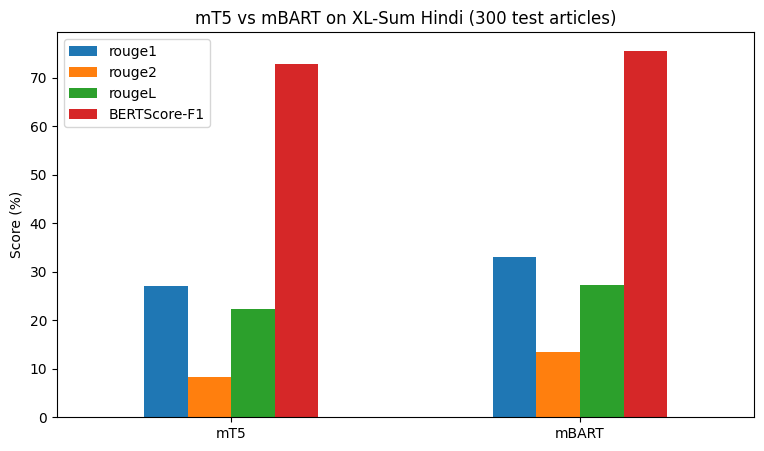

In [10]:
# comparison table and bar chart
import matplotlib.pyplot as plt

comparison = pd.DataFrame(results).T
display(comparison.round(2))

comparison[["rouge1", "rouge2", "rougeL", "BERTScore-F1"]].plot(kind="bar", figsize=(9, 5))
plt.title("mT5 vs mBART on XL-Sum Hindi (300 test articles)")
plt.ylabel("Score (%)")
plt.xticks(rotation=0)
plt.show()

In [11]:
# side-by-side examples to include in your report
for i in range(3):
    print(f"--- Example {i + 1} ---")
    print("Reference:", test_df.loc[i, "summary"])
    print("mT5      :", mt5_preds[i])
    print("mBART    :", mbart_preds[i], "\n")

--- Example 1 ---
Reference: भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा का नाम बड़ा अदब से लिया जाता है. उनके 94वें जन्मदिन के मौके पर दिल्ली में बीआर चोपड़ा की फ़िल्मों का विशेष उत्सव मनाया जा रहा है.
mT5      : बॉलीवुड अभिनेत्री बीआर चोपड़ा ने अपने भाई और मशहूर फ़ेस्टिवल में इंसाफ़ का तराज़ू फ़िल्में बनाईं.
mBART    : मशहूर फ़िल्मकार बीआर चोपड़ा का 125वां फ़िल्मोत्सव शुरू हो गया है. 

--- Example 2 ---
Reference: अफ़ग़ानिस्तान के कंधार में तालेबान चरमपंथियों ने जेल पर हमला करके सैकड़ों क़ैदियों को छुड़ा दिया है.
mT5      : पाकिस्तान के कंधार शहर में एक हज़ार क़ैदी निकल गए हैं.
mBART    : अफ़ग़ान प्रांत के कंधार शहर में तालेबान चरमपंथियों द्वारा किए गए एक हमले में कम से कम 40 लोगों की मौत हो गई है. 

--- Example 3 ---
Reference: गिनीज़ वर्ल्ड रिकॉर्ड में अपना नाम दर्ज कराने की उम्मीद में एक बुल्गारियाई व्यक्ति ने बोरे में बंद होकर दो किलोमीटर तक तैराकी की.
mT5      : अमरीका के राष्ट्रपति जेन पेत्कोव ने कहा है कि मैसेडोनिया की ऑरिड झील पर तैराकी प्रदर्शन को विधिवत रिकॉर्ड किया गया 